**1. Entorno y archivos protegidos**

Se utiliza el entorno tesis-fcl y una configuración fija. Se protegen los archivos anteriores mediante hashes; solo se crean el notebook 07 y los reportes nuevos de Sprint 6.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, platform, sys
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.base import clone
ROOT=Path.cwd().resolve()
if ROOT.name=="notebooks": ROOT=ROOT.parent
assert Path(sys.prefix).name=="tesis-fcl",sys.executable
NB=ROOT/"notebooks/07_baseline_variantes.ipynb"
OUT=ROOT/"reports/sprint_06"
OUT.mkdir(parents=True,exist_ok=True)
assert (ROOT/"README.md").exists()
archivos_previos=[ROOT/"README.md",*sorted(p for carpeta in ["data","reports","notebooks","src"] for p in (ROOT/carpeta).rglob("*")
    if p.is_file() and p!=NB and OUT not in p.parents and "__pycache__" not in p.parts and ".ipynb_checkpoints" not in p.parts)]
def hashes_previos():return {str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in archivos_previos}
hashes_antes=hashes_previos()
SEED=42
np.random.seed(SEED)
ALPHA=1.0
etapas=[]
versiones={p:metadata.version(p) for p in ["pandas","numpy","scikit-learn","matplotlib","nbformat","nbclient"]}
interpretaciones={}
plt.rcParams.update({"axes.grid":True,"grid.alpha":.25})
display(pd.Series(versiones,name="version").to_frame())
interpretaciones[1]=f"Se ejecuta Python {platform.python_version()} en tesis-fcl. Ridge usara alpha=1.0, sin busqueda de hiperparametros."
etapas.append(1)

,version
pandas,3.0.6
numpy,2.5.4
scikit-learn,1.9.1
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0


Se ejecuta Python 3.12.15 en tesis-fcl. Ridge usara alpha=1.0, sin busqueda de hiperparametros.

**2. Revisión de insumos, diccionarios y auditorías**

Se comprueban dimensiones, tipos e igualdad de las columnas compartidas entre los tres paneles. Se revisan notebooks y auditorías existentes sin ejecutarlos ni modificarlos.

In [2]:
nombres=["features_financieras.csv","panel_financiero_macroeconomico.csv","panel_financiero_macro_bursatil.csv"]
frames={name:pd.read_csv(ROOT/"data/processed"/name,dtype={"RPJ":"string","RUC":"string"},float_precision="round_trip") for name in nombres}
fin,macro,datos=[frames[x] for x in nombres]
assert fin.shape==(4221,57) and macro.shape==(4221,62) and datos.shape==(4221,68)
pd.testing.assert_frame_equal(fin,macro[fin.columns],check_exact=True)
pd.testing.assert_frame_equal(macro,datos[macro.columns],check_exact=True)
catalogo=pd.read_csv(ROOT/"reports/diccionario_integracion_bursatil.csv",keep_default_na=False)
assert catalogo.variable.tolist()==datos.columns.tolist()
revisados=[]
for p in sorted((ROOT/"notebooks").glob("*.ipynb")):
    if p.name[:2] in ["02","03","04","05","06"]:
        contenido=json.loads(p.read_text());revisados.append({"archivo":str(p.relative_to(ROOT)),"celdas":len(contenido["cells"]),"tipo":"notebook"})
for p in sorted((ROOT/"reports").glob("*auditoria*.md")):
    texto=p.read_text(encoding="utf-8");revisados.append({"archivo":str(p.relative_to(ROOT)),"celdas":None,"tipo":"auditoria"})
for rel in ["README.md","reports/diccionario_features.md","reports/trazabilidad_variables.md","src/feature_engineering.py"]:
    texto=(ROOT/rel).read_text(encoding="utf-8")
    revisados.append({"archivo":rel,"celdas":None,"tipo":"arquitectura/metodo"})
display(pd.DataFrame([{"archivo":k,"filas":len(v),"columnas":v.shape[1],"inicio":v.Ejercicio.min(),"fin":v.Ejercicio.max()} for k,v in frames.items()]))
display(datos.dtypes.astype(str).rename("tipo").to_frame())
display(pd.DataFrame(revisados))
interpretaciones[2]="Las fuentes tienen 4221 x 57, 4221 x 62 y 4221 x 68; sus columnas compartidas son exactamente iguales. Cubren 2005–2025."
etapas.append(2)

,archivo,filas,columnas,inicio,fin
0,features_financieras.csv,4221,57,2005,2025
1,panel_financiero_macroeconomico.csv,4221,62,2005,2025
2,panel_financiero_macro_bursatil.csv,4221,68,2005,2025


,tipo
RPJ,string
RUC,string
NombreEmpresa,str
Ejercicio,int64
TipoEmpresa,str
...,...
volatilidad_diaria_anualizada_pct,float64
monto_renta_variable_anual_millones_pen,float64
transicion_metodologica_2015,bool
regimen_documentado,str


,archivo,celdas,tipo
0,notebooks/02_feature_engineering.ipynb,12.0,notebook
1,notebooks/03_extraccion_macroeconomica.ipynb,31.0,notebook
2,notebooks/04_integracion_datos.ipynb,31.0,notebook
3,notebooks/05_extraccion_bursatil.ipynb,43.0,notebook
4,notebooks/06_integracion_bursatil.ipynb,34.0,notebook
5,reports/auditoria_extraccion_bursatil.md,NaN,auditoria
6,reports/auditoria_extraccion_macroeconomica.md,NaN,auditoria
7,reports/auditoria_feature_engineering.md,NaN,auditoria
8,reports/auditoria_integracion_bursatil.md,NaN,auditoria
9,reports/auditoria_integracion_datos.md,NaN,auditoria


Las fuentes tienen 4221 x 57, 4221 x 62 y 4221 x 68; sus columnas compartidas son exactamente iguales. Cubren 2005–2025.

**3. Objetivo, moneda y particiones originales**

El objetivo es FCO(t+1) + CAPEX reportado(t+1), invalidado si CAPEX es positivo; es una aproximación, no FCFF validado. Se verifica la unión al año siguiente y se evalúa cada moneda por separado.

In [3]:
assert datos.anio_objetivo.eq(datos.Ejercicio+1).all()
assert not datos.duplicated(["RPJ","Ejercicio"]).any()
fuente_futura=fin[["RPJ","Ejercicio","Moneda","FCO","CAPEX_reportado"]].copy()
fuente_futura["valor_futuro"]=(fuente_futura.FCO+fuente_futura.CAPEX_reportado).where(~fuente_futura.CAPEX_reportado.gt(0))
fuente_futura["Ejercicio"]-=1
check=fin[["RPJ","Ejercicio"]].merge(fuente_futura[["RPJ","Ejercicio","Moneda","valor_futuro"]],on=["RPJ","Ejercicio"],how="left",validate="one_to_one")
np.testing.assert_allclose(fin.objetivo_fcl_t1,check.valor_futuro,rtol=0,atol=0,equal_nan=True)
assert fin.moneda_objetivo.fillna("AUSENTE").eq(check.Moneda.fillna("AUSENTE")).all()
elegible=datos.objetivo_fcl_t1.notna() & datos.Moneda.eq(datos.moneda_objetivo)
assert elegible.equals(datos.utilizable_supervisado)
assert datos.loc[elegible,"particion"].isin(["entrenamiento","prueba"]).all()
muestra=datos.loc[elegible].copy()
muestra["id_fila"]=muestra.index
assert muestra.shape[0]==3560
assert muestra.Moneda.eq(muestra.moneda_objetivo).all()
assert muestra.loc[muestra.particion.eq("entrenamiento"),"anio_objetivo"].max()<muestra.loc[muestra.particion.eq("prueba"),"anio_objetivo"].min()
monedas=sorted(muestra.Moneda.unique())
assert len(monedas)==2
conteos=muestra.groupby(["Moneda","particion"]).agg(n=("RPJ","size"),empresas=("RPJ","nunique"),ejercicio_min=("Ejercicio","min"),ejercicio_max=("Ejercicio","max"),objetivo_min=("anio_objetivo","min"),objetivo_max=("anio_objetivo","max"))
display(conteos)
print("Escala monetaria no acreditada: no se mezclan monedas ni se convierten unidades.")
interpretaciones[3]="Se conservan 3560 casos: 2869 de entrenamiento y 691 de prueba. Soles aporta 2516/599 y la etiqueta de dolares 'D lares' 353/92; no se agregan errores entre monedas."
etapas.append(3)

n  empresas  ejercicio_min  ejercicio_max  \
Moneda  particion                                                     
D lares entrenamiento   353        49           2005           2020   
        prueba           92        26           2021           2024   
Soles   entrenamiento  2516       269           2005           2020   
        prueba          599       161           2021           2024   

                       objetivo_min  objetivo_max  
Moneda  particion                                  
D lares entrenamiento          2006          2021  
        prueba                 2022          2025  
Soles   entrenamiento          2006          2021  
        prueba                 2022          2025

Escala monetaria no acreditada: no se mezclan monedas ni se convierten unidades.


Se conservan 3560 casos: 2869 de entrenamiento y 691 de prueba. Soles aporta 2516/599 y la etiqueta de dolares 'D lares' 353/92; no se agregan errores entre monedas.

**4. Predictores por experimento y riesgos de fuga**

Se heredan los roles del catálogo y el subconjunto financiero de 19 variables sin tres redundancias exactas. Las fuentes, identificadores, año objetivo y controles quedan fuera de X; los derivados de FCL hasta t no equivalen al objetivo t+1.

In [4]:
fin22=catalogo.loc[catalogo.origen.eq("SMV/Feature Engineering") & catalogo.predictor_candidato,"variable"].tolist()
redundantes={"fcl_activo","FCO_mean3_previa","FCL_preliminar_mean3_previa"}
FIN=[v for v in fin22 if v not in redundantes]
MACRO=["inflacion_lima_dic_dic_pct","tipo_cambio_promedio_soles_usd","tasa_referencia_promedio_pct","crecimiento_pbi_real_pct"]
BOLSA=["rentabilidad_indice_anual_pct","volatilidad_diaria_anualizada_pct","monto_renta_variable_anual_millones_pen"]
EXPERIMENTOS={"E0_financiero":FIN,"E1_macroeconomico":FIN+MACRO,"E2_bursatil":FIN+MACRO+BOLSA}
assert len(fin22)==22 and len(FIN)==19
for cols in EXPERIMENTOS.values():
    assert catalogo.set_index("variable").loc[cols,"predictor_candidato"].all()
    assert all(pd.api.types.is_numeric_dtype(muestra[c]) for c in cols)
    assert not {"objetivo_fcl_t1","anio_objetivo","particion","moneda_objetivo","pbi_real_millones_soles_2007"}.intersection(cols)
train=datos.particion.eq("entrenamiento")
x=datos.loc[train,["fcl_activo","fco_activo","inversion_capex_activo"]].dropna()
np.testing.assert_allclose(x.fcl_activo,x.fco_activo-x.inversion_capex_activo,rtol=1e-12,atol=1e-12)
for prefijo in ["FCO","FCL_preliminar"]:
    cols=[f"{prefijo}_lag{i}" for i in [1,2,3]]
    x=datos.loc[train,[*cols,f"{prefijo}_mean3_previa"]].dropna()
    np.testing.assert_allclose(x[f"{prefijo}_mean3_previa"],x[cols].mean(axis=1),rtol=1e-12,atol=1e-8)
# Verificar rezagos reales: segmentos rompen al faltar año o cambiar moneda.
ordenado=fin.sort_values(["RPJ","Ejercicio"]).copy()
prev=ordenado.groupby("RPJ")[["Ejercicio","Moneda"]].shift()
segmento=(ordenado.Ejercicio.ne(prev.Ejercicio+1)|ordenado.Moneda.ne(prev.Moneda)).cumsum()
for prefijo in ["FCO","FCL_preliminar"]:
    valor=ordenado[prefijo] if prefijo=="FCO" else ordenado[prefijo].where(~ordenado.CAPEX_reportado.gt(0))
    for lag in [1,2,3]:
        esperado=valor.groupby(segmento).shift(lag)
        np.testing.assert_allclose(ordenado[f"{prefijo}_lag{lag}"],esperado,rtol=0,atol=0,equal_nan=True)
    std=valor.groupby(segmento).transform(lambda s:s.shift(1).rolling(3,min_periods=3).std(ddof=1))
    np.testing.assert_allclose(ordenado[f"{prefijo}_std3_previa"],std,rtol=1e-12,atol=1e-8,equal_nan=True)
display(pd.DataFrame([{"experimento":k,"n_predictores":len(v),"numericos":len(v),"categoricos":0} for k,v in EXPERIMENTOS.items()]))
print("Se excluyen tres redundancias por definicion, no por desempeno de prueba:",sorted(redundantes))
interpretaciones[4]="E0 usa 19 predictores; E1, 23; E2, 26. Se verifican las identidades redundantes en entrenamiento y los rezagos financieros por segmento anual y moneda; ninguna categoria contextual se incorpora automaticamente."
etapas.append(4)

,experimento,n_predictores,numericos,categoricos
0,E0_financiero,19,19,0
1,E1_macroeconomico,23,23,0
2,E2_bursatil,26,26,0


Se excluyen tres redundancias por definicion, no por desempeno de prueba: ['FCL_preliminar_mean3_previa', 'FCO_mean3_previa', 'fcl_activo']


E0 usa 19 predictores; E1, 23; E2, 26. Se verifican las identidades redundantes en entrenamiento y los rezagos financieros por segmento anual y moneda; ninguna categoria contextual se incorpora automaticamente.

**5. Sensibilidad conservadora de disponibilidad temporal**

No hay fechas históricas de publicación ni versiones disponibles al pronosticar. Se mantienen los experimentos contemporáneos y se añade una sensibilidad que usa indicadores externos de t−1, unidos por año exacto y sin rellenar desde t.

In [5]:
externas=MACRO+BOLSA
macro_anual=pd.read_csv(ROOT/"data/processed/macroeconomia_peru_2005_2025.csv",float_precision="round_trip")
bolsa_anual=pd.read_csv(ROOT/"data/processed/bursatil_mercado_anual.csv",float_precision="round_trip")
anual=macro_anual[["anio",*MACRO]].merge(bolsa_anual[["anio",*BOLSA]],on="anio",how="outer",validate="one_to_one").set_index("anio").sort_index()
rezagada=muestra.copy(deep=True)
for v in externas:
    esperado=muestra.Ejercicio.sub(1).map(anual[v])
    rezagada[v]=esperado
    pd.testing.assert_series_equal(rezagada[v],esperado.rename(v),check_exact=True)
for y in muestra.Ejercicio.unique():
    if y-1 in anual.index:
        for v in externas:
            np.testing.assert_allclose(rezagada.loc[rezagada.Ejercicio.eq(y),v],anual.loc[y-1,v],rtol=0,atol=0,equal_nan=True)
assert rezagada.loc[rezagada.Ejercicio.eq(2005),externas].isna().all().all()
pd.testing.assert_frame_equal(rezagada[["id_fila","RPJ","RUC","objetivo_fcl_t1","particion"]],muestra[["id_fila","RPJ","RUC","objetivo_fcl_t1","particion"]],check_exact=True)
print("Rezagos externos no disponibles en 2005:",int(rezagada.Ejercicio.eq(2005).sum()),"filas; se conservan con imputacion aprendida solo en entrenamiento.")
print("El rezago no certifica vintage ni la disponibilidad de los estados financieros de t.")
interpretaciones[5]=f"La sensibilidad usa anio=Ejercicio−1 y conserva las mismas 3560 filas. Los {int(rezagada.Ejercicio.eq(2005).sum())} casos de 2005 no tienen base externa 2004 completa y permanecen como faltantes antes del Pipeline."
etapas.append(5)

Rezagos externos no disponibles en 2005: 147 filas; se conservan con imputacion aprendida solo en entrenamiento.
El rezago no certifica vintage ni la disponibilidad de los estados financieros de t.


La sensibilidad usa anio=Ejercicio−1 y conserva las mismas 3560 filas. Los 147 casos de 2005 no tienen base externa 2004 completa y permanecen como faltantes antes del Pipeline.

**6. Faltantes, distribución y extremos del entrenamiento**

Se examinan predictores y FCL por moneda usando solo entrenamiento. El RIQ identifica extremos de forma diagnóstica; no se eliminan filas, se winsoriza ni se ajustan transformaciones del objetivo.

,moneda,n,min,mediana,max,asimetria,extremos_RIQ
0,D lares,353,-1858184.0,24651.0,1909766.0,1.080578,52
1,Soles,2516,-11333370.0,8934.0,17466182.0,8.273317,484


,moneda,variable,faltantes_train,extremos_train,desviacion_train
0,D lares,pasivo_activo,0,1,0.232355
1,D lares,margen_neto,27,22,0.281015
2,D lares,rentabilidad_activo_cierre,0,43,0.147790
3,D lares,rotacion_activo_cierre,27,28,0.732239
4,D lares,fco_activo,10,29,0.204487
5,D lares,fco_ingresos,36,14,0.301351
6,D lares,inversion_capex_activo,0,16,0.056670
7,D lares,crecimiento_ActivoTotal,52,19,0.227971
8,D lares,crecimiento_TotalIngreso,70,19,0.798044
9,D lares,cambio_FCO_activo_previo,71,34,0.191392


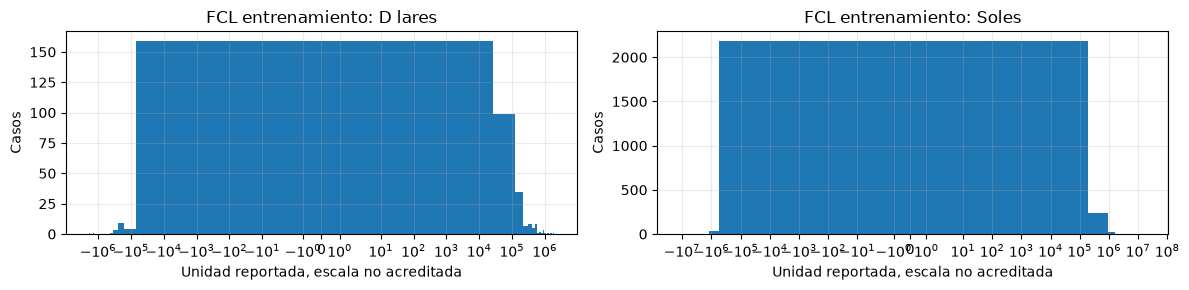

In [6]:
calidad=[]; distribucion=[]
for moneda in monedas:
    t=muestra.loc[muestra.Moneda.eq(moneda)&muestra.particion.eq("entrenamiento")]
    y=t.objetivo_fcl_t1
    q1,q3=y.quantile([.25,.75]);iqr=q3-q1
    distribucion.append({"moneda":moneda,"n":len(y),"min":y.min(),"mediana":y.median(),"max":y.max(),"asimetria":y.skew(),"extremos_RIQ":int(((y<q1-1.5*iqr)|(y>q3+1.5*iqr)).sum())})
    for v in EXPERIMENTOS["E2_bursatil"]:
        s=t[v];a,b=s.quantile([.25,.75]);d=b-a
        calidad.append({"moneda":moneda,"variable":v,"faltantes_train":int(s.isna().sum()),"extremos_train":int((s.lt(a-1.5*d)|s.gt(b+1.5*d)).sum()),"desviacion_train":s.std()})
calidad=pd.DataFrame(calidad);distribucion=pd.DataFrame(distribucion)
assert not np.isinf(muestra[EXPERIMENTOS["E2_bursatil"]].to_numpy()).any()
display(distribucion)
display(calidad)
fig,axs=plt.subplots(1,2,figsize=(12,3))
for ax,moneda in zip(axs,monedas):
    y=muestra.loc[muestra.Moneda.eq(moneda)&muestra.particion.eq("entrenamiento"),"objetivo_fcl_t1"]
    ax.hist(y,bins=40);ax.set(title=f"FCL entrenamiento: {moneda}",xlabel="Unidad reportada, escala no acreditada",ylabel="Casos");ax.set_xscale("symlog")
fig.tight_layout();plt.show()
interpretaciones[6]="El entrenamiento muestra " + "; ".join(f"{r.moneda}: asimetria {r.asimetria:.2f}, {r.extremos_RIQ} objetivos extremos" for r in distribucion.itertuples()) + ". Se conservan todos los valores."
etapas.append(6)

El entrenamiento muestra D lares: asimetria 1.08, 52 objetivos extremos; Soles: asimetria 8.27, 484 objetivos extremos. Se conservan todos los valores.

**7. Ridge y preparación dentro del Pipeline**

Ridge minimiza el error cuadrático más alpha × suma de coeficientes al cuadrado (L2); el intercepto no se penaliza. La mediana y StandardScaler se ajustan solo en entrenamiento para hacer comparable la penalización entre predictores.

In [7]:
def crear_modelo(columnas,escala="standard"):
    escalador=StandardScaler() if escala=="standard" else RobustScaler(quantile_range=(25,75))
    numerico=Pipeline([("imputer",SimpleImputer(strategy="median",keep_empty_features=True)),("scaler",escalador)])
    preparador=ColumnTransformer([("numericas",numerico,columnas)],remainder="drop",verbose_feature_names_out=False)
    return Pipeline([("preparacion",preparador),("ridge",Ridge(alpha=ALPHA,solver="svd",fit_intercept=True))])
modelos={};predicciones=[];ajustes=[]
def ejecutar(escenario,tabla,escala):
    for moneda in monedas:
        tr=tabla.loc[tabla.Moneda.eq(moneda)&tabla.particion.eq("entrenamiento")]
        te=tabla.loc[tabla.Moneda.eq(moneda)&tabla.particion.eq("prueba")]
        assert len(tr)>0 and len(te)>0
        for exp,cols in EXPERIMENTOS.items():
            modelo=crear_modelo(cols,escala)
            modelo.fit(tr[cols],tr.objetivo_fcl_t1)
            numerico=modelo.named_steps["preparacion"].named_transformers_["numericas"]
            imputer=numerico.named_steps["imputer"];scaler=numerico.named_steps["scaler"]
            medianas=tr[cols].median().fillna(0).to_numpy()
            np.testing.assert_allclose(imputer.statistics_,medianas,rtol=1e-12)
            z=imputer.transform(tr[cols])
            if escala=="standard":
                np.testing.assert_allclose(scaler.mean_,z.mean(axis=0),rtol=1e-12,atol=1e-12)
                np.testing.assert_allclose(scaler.var_,z.var(axis=0),rtol=1e-12,atol=1e-12)
                assert int(scaler.n_samples_seen_)==len(tr)
            else:np.testing.assert_allclose(scaler.center_,np.median(z,axis=0),rtol=1e-12,atol=1e-12)
            modelos[(escenario,moneda,exp)]=modelo
            ajustes.append({"escenario":escenario,"moneda":moneda,"experimento":exp,"escala":escala,"n_ajuste":len(tr),"predictores":cols,
                "ids_ajuste":tr.id_fila.tolist(),"medianas":imputer.statistics_.tolist(),
                "hash_X_train":hashlib.sha256(pd.util.hash_pandas_object(tr[cols],index=True).values.tobytes()).hexdigest()})
            for particion,t in [("entrenamiento",tr),("prueba",te)]:
                yhat=modelo.predict(t[cols]);assert np.isfinite(yhat).all()
                p=t[["id_fila","RPJ","RUC","Ejercicio","anio_objetivo","TipoSector","revision_interanual"]].copy()
                p["moneda"]=moneda;p["escenario"]=escenario;p["experimento"]=exp;p["particion"]=particion
                p["y_real"]=t.objetivo_fcl_t1.to_numpy();p["y_predicho"]=yhat;p["error"]=yhat-p.y_real
                predicciones.append(p)
print("ColumnTransformer: solo predictores numericos autorizados; no hay categorias elegibles en el catalogo.")
interpretaciones[7]="La configuracion usa mediana, StandardScaler y Ridge(alpha=1.0, solver=svd); cada ajuste registra sus ids y verifica estadisticas calculadas solo con entrenamiento."
etapas.append(7)

ColumnTransformer: solo predictores numericos autorizados; no hay categorias elegibles en el catalogo.


La configuracion usa mediana, StandardScaler y Ridge(alpha=1.0, solver=svd); cada ajuste registra sus ids y verifica estadisticas calculadas solo con entrenamiento.

**8. Entrenamiento de los tres experimentos principales**

Los tres experimentos contemporáneos usan las mismas observaciones y alpha=1.0, con un modelo independiente por moneda. No se optimizan hiperparámetros ni se usan las etiquetas de prueba al ajustar.

In [8]:
ejecutar("principal",muestra,"standard")
assert len(modelos)==6
for moneda in monedas:
    ids=[a["ids_ajuste"] for a in ajustes if a["moneda"]==moneda and a["escenario"]=="principal"]
    assert ids[0]==ids[1]==ids[2]
print("Modelos principales ajustados:",len(modelos))
interpretaciones[8]="Se ajustaron seis modelos: tres experimentos por cada moneda. Las observaciones de entrenamiento son identicas entre experimentos y no se han elegido parametros con prueba."
etapas.append(8)

Modelos principales ajustados: 6


Se ajustaron seis modelos: tres experimentos por cada moneda. Las observaciones de entrenamiento son identicas entre experimentos y no se han elegido parametros con prueba.

**9. Sensibilidad con indicadores externos rezagados**

Se repiten los tres experimentos con externos de t−1, manteniendo los predictores financieros y todas las observaciones. Esta comparación no reemplaza los experimentos principales ni acredita disponibilidad real de los datos revisados.

In [9]:
ejecutar("rezago_externo_t_1",rezagada,"standard")
for moneda in monedas:
    for exp in EXPERIMENTOS:
        a=modelos[("principal",moneda,"E0_financiero")]
        b=modelos[("rezago_externo_t_1",moneda,"E0_financiero")]
        np.testing.assert_allclose(a.named_steps["ridge"].coef_,b.named_steps["ridge"].coef_,rtol=0,atol=0)
print("Modelos con rezagos ajustados:",6)
interpretaciones[9]="La sensibilidad conserva las 3560 observaciones. E0 reproduce exactamente los coeficientes principales, pues sus variables financieras no se modifican."
etapas.append(9)

Modelos con rezagos ajustados: 6


La sensibilidad conserva las 3560 observaciones. E0 reproduce exactamente los coeficientes principales, pues sus variables financieras no se modifican.

**10. Sensibilidad al escalamiento sin cambiar el algoritmo**

Se repite Ridge con RobustScaler, que centra por mediana y escala por RIQ aprendido en entrenamiento. Se compara como sensibilidad predefinida; no se elige el escalador ganador para reajustar el experimento principal.

In [10]:
ejecutar("sensibilidad_robust",muestra,"robust")
pred=pd.concat(predicciones,ignore_index=True)
assert not pred.duplicated(["escenario","experimento","moneda","id_fila"]).any()
for (_,_,_),g in pred.groupby(["escenario","experimento","moneda"]):
    esperado=muestra.loc[muestra.Moneda.eq(g.moneda.iloc[0]),"id_fila"]
    assert set(g.id_fila)==set(esperado)
assert len(pred)==3560*3*3
print("Predicciones exportables:",len(pred),"| Modelos Ridge:",len(modelos))
interpretaciones[10]="Se ajustan 18 modelos Ridge en total; las tres configuraciones generan 32040 predicciones sin perder observaciones ni producir valores infinitos."
etapas.append(10)

Predicciones exportables: 32040 | Modelos Ridge: 18


Se ajustan 18 modelos Ridge en total; las tres configuraciones generan 32040 predicciones sin perder observaciones ni producir valores infinitos.

**11. Métricas de entrenamiento y prueba por moneda**

Se calculan MAE, RMSE, R² y error medio (predicción − valor real), con n explícito. Las métricas monetarias se comparan solo dentro de cada moneda y no se promedian entre soles y dólares.

In [11]:
def metricas(y,p):
    y=np.asarray(y,dtype=float);p=np.asarray(p,dtype=float)
    assert len(y)==len(p) and len(y)>0 and np.isfinite(y).all() and np.isfinite(p).all()
    mae=mean_absolute_error(y,p);rmse=root_mean_squared_error(y,p)
    r2=r2_score(y,p,force_finite=False) if len(y)>=2 and np.var(y)>0 else np.nan
    np.testing.assert_allclose(mae,np.mean(np.abs(p-y)),rtol=1e-12)
    np.testing.assert_allclose(rmse,np.sqrt(np.mean((p-y)**2)),rtol=1e-12)
    if np.isfinite(r2):np.testing.assert_allclose(r2,1-np.sum((y-p)**2)/np.sum((y-y.mean())**2),rtol=1e-12,atol=1e-12)
    return {"n":len(y),"MAE":float(mae),"RMSE":float(rmse),"R2":float(r2),"error_medio":float(np.mean(p-y))}
filas=[]
for keys,g in pred.groupby(["escenario","moneda","experimento","particion"],sort=True):
    escenario,moneda,exp,particion=keys
    filas.append(dict(escenario=escenario,moneda=moneda,experimento=exp,particion=particion,n_predictores=len(EXPERIMENTOS[exp]),alpha=ALPHA,**metricas(g.y_real,g.y_predicho)))
resultados=pd.DataFrame(filas)
base=resultados.loc[resultados.experimento.eq("E0_financiero"),["escenario","moneda","particion","MAE","RMSE"]].rename(columns={"MAE":"MAE_baseline","RMSE":"RMSE_baseline"})
comparacion=resultados.merge(base,on=["escenario","moneda","particion"],validate="many_to_one")
for m in ["MAE","RMSE"]:
    # Valores positivos indican reduccion del error respecto a E0.
    comparacion[f"mejora_{m}_pct"]=(comparacion[f"{m}_baseline"]-comparacion[m]).div(comparacion[f"{m}_baseline"].where(comparacion[f"{m}_baseline"].ne(0))).mul(100)
principales=comparacion.loc[comparacion.escenario.eq("principal")].copy()
display(principales[["moneda","experimento","particion","n","n_predictores","MAE","RMSE","R2","error_medio","mejora_MAE_pct","mejora_RMSE_pct"]].round(4))
interpretaciones[11]="MAE de prueba E0/E1/E2: " + "; ".join(m+" "+"/".join(f"{v:.0f}" for v in principales.loc[principales.moneda.eq(m)&principales.particion.eq("prueba"),"MAE"]) for m in monedas) + ". Todos los R2 principales de prueba son negativos."
etapas.append(11)

,moneda,experimento,particion,n,n_predictores,MAE,RMSE,R2,error_medio,mejora_MAE_pct,mejora_RMSE_pct
0,D lares,E0_financiero,entrenamiento,353,19,110635.6229,2.152702e+05,0.3953,0.0000,0.0000,0.0000
1,D lares,E0_financiero,prueba,92,19,228054.3656,8.047555e+05,-2.0305,95644.0230,0.0000,0.0000
2,D lares,E1_macroeconomico,entrenamiento,353,23,112972.6985,2.137630e+05,0.4037,0.0000,-2.1124,0.7002
3,D lares,E1_macroeconomico,prueba,92,23,317991.4029,1.343050e+06,-7.4405,247181.6748,-39.4367,-66.8892
4,D lares,E2_bursatil,entrenamiento,353,26,115446.8203,2.116589e+05,0.4154,0.0000,-4.3487,1.6776
5,D lares,E2_bursatil,prueba,92,26,237509.5735,7.594931e+05,-1.6992,136772.5790,-4.1460,5.6244
6,Soles,E0_financiero,entrenamiento,2516,19,137535.9986,6.034477e+05,0.1799,0.0000,0.0000,0.0000
7,Soles,E0_financiero,prueba,599,19,379977.4371,1.424709e+06,-1.4901,157975.7289,0.0000,0.0000
8,Soles,E1_macroeconomico,entrenamiento,2516,23,147217.0152,6.024045e+05,0.1827,-0.0000,-7.0389,0.1729
9,Soles,E1_macroeconomico,prueba,599,23,442301.8671,1.445745e+06,-1.5642,209324.9153,-16.4021,-1.4765


MAE de prueba E0/E1/E2: D lares 228054/317991/237510; Soles 379977/442302/426780. Todos los R2 principales de prueba son negativos.

**12. Comparación cuantitativa de variantes y sensibilidades**

Se identifican los menores errores del experimento principal por moneda y por métrica, sin mezclar sensibilidades en la elección. Los cambios de resultados con rezagos o escalamiento se presentan como límites de robustez.

In [12]:
prueba=comparacion.loc[comparacion.particion.eq("prueba")].copy()
display(prueba[["escenario","moneda","experimento","MAE","RMSE","R2","mejora_MAE_pct","mejora_RMSE_pct"]].round(4))
mejores=[]
for moneda in monedas:
    g=principales.loc[principales.moneda.eq(moneda)&principales.particion.eq("prueba")]
    for metrica in ["MAE","RMSE"]:
        r=g.loc[g[metrica].idxmin()]
        mejores.append({"moneda":moneda,"criterio":metrica,"experimento":r.experimento,"valor":float(r[metrica])})
mejores=pd.DataFrame(mejores)
display(mejores)
interpretaciones[12]="Menor error: " + "; ".join(f"{m}: MAE {mejores.loc[mejores.moneda.eq(m)&mejores.criterio.eq('MAE'),'experimento'].item()}, RMSE {mejores.loc[mejores.moneda.eq(m)&mejores.criterio.eq('RMSE'),'experimento'].item()}" for m in monedas) + ". No hay superioridad general de las variantes."
etapas.append(12)

,escenario,moneda,experimento,MAE,RMSE,R2,mejora_MAE_pct,mejora_RMSE_pct
1,principal,D lares,E0_financiero,228054.3656,8.047555e+05,-2.0305,0.0000,0.0000
3,principal,D lares,E1_macroeconomico,317991.4029,1.343050e+06,-7.4405,-39.4367,-66.8892
5,principal,D lares,E2_bursatil,237509.5735,7.594931e+05,-1.6992,-4.1460,5.6244
7,principal,Soles,E0_financiero,379977.4371,1.424709e+06,-1.4901,0.0000,0.0000
9,principal,Soles,E1_macroeconomico,442301.8671,1.445745e+06,-1.5642,-16.4021,-1.4765
11,principal,Soles,E2_bursatil,426780.0103,1.438297e+06,-1.5379,-12.3172,-0.9537
13,rezago_externo_t_1,D lares,E0_financiero,228054.3656,8.047555e+05,-2.0305,0.0000,0.0000
15,rezago_externo_t_1,D lares,E1_macroeconomico,274983.3628,9.252073e+05,-3.0055,-20.5780,-14.9675
17,rezago_externo_t_1,D lares,E2_bursatil,249943.0616,6.076990e+05,-0.7281,-9.5980,24.4865
19,rezago_externo_t_1,Soles,E0_financiero,379977.4371,1.424709e+06,-1.4901,0.0000,0.0000


,moneda,criterio,experimento,valor
0,D lares,MAE,E0_financiero,2.280544e+05
1,D lares,RMSE,E2_bursatil,7.594931e+05
2,Soles,MAE,E0_financiero,3.799774e+05
3,Soles,RMSE,E0_financiero,1.424709e+06


Menor error: D lares: MAE E0_financiero, RMSE E2_bursatil; Soles: MAE E0_financiero, RMSE E0_financiero. No hay superioridad general de las variantes.

**13. Valores reales, predicciones y distribución de errores**

Se grafican únicamente los experimentos principales de prueba, separados por moneda. La diagonal indica predicción exacta; los errores positivos representan sobreestimación del FCL.

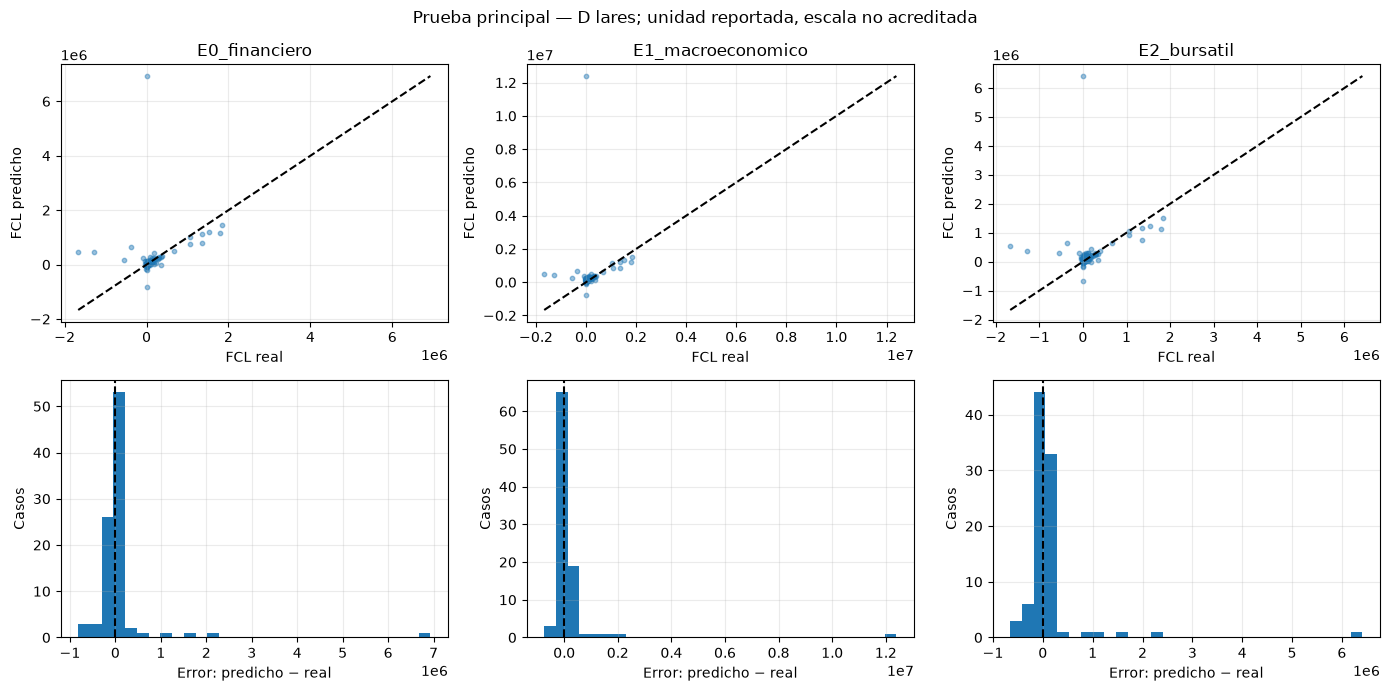

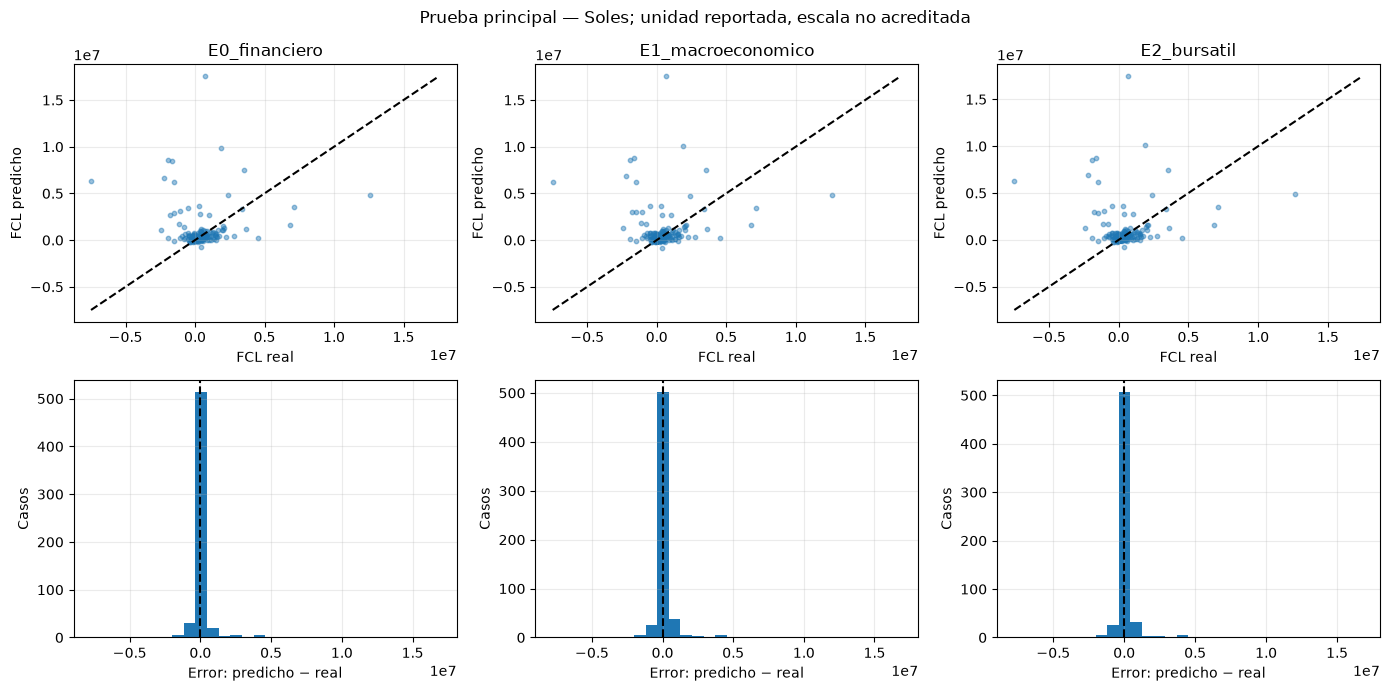

In [13]:
for moneda in monedas:
    fig,axs=plt.subplots(2,3,figsize=(14,7))
    for j,exp in enumerate(EXPERIMENTOS):
        g=pred.loc[pred.escenario.eq("principal")&pred.moneda.eq(moneda)&pred.particion.eq("prueba")&pred.experimento.eq(exp)]
        ax=axs[0,j];ax.scatter(g.y_real,g.y_predicho,s=10,alpha=.45)
        lo=min(g.y_real.min(),g.y_predicho.min());hi=max(g.y_real.max(),g.y_predicho.max())
        ax.plot([lo,hi],[lo,hi],color="black",linestyle="--");ax.set(title=exp,xlabel="FCL real",ylabel="FCL predicho")
        axs[1,j].hist(g.error,bins=30);axs[1,j].axvline(0,color="black",linestyle="--");axs[1,j].set(xlabel="Error: predicho − real",ylabel="Casos")
    fig.suptitle(f"Prueba principal — {moneda}; unidad reportada, escala no acreditada")
    fig.tight_layout();plt.show()
interpretaciones[13]="Los graficos contienen 599 casos de prueba en soles y 92 en dolares por experimento, sin eliminar valores extremos. Los ejes conservan las unidades reportadas."
etapas.append(13)

Los graficos contienen 599 casos de prueba en soles y 92 en dolares por experimento, sin eliminar valores extremos. Los ejes conservan las unidades reportadas.

**14. Comparación gráfica de errores, R² y residuos por año**

Se presentan MAE, RMSE y R² de entrenamiento y prueba por moneda. Los errores anuales se agrupan por anio_objetivo, que nunca forma parte de X.

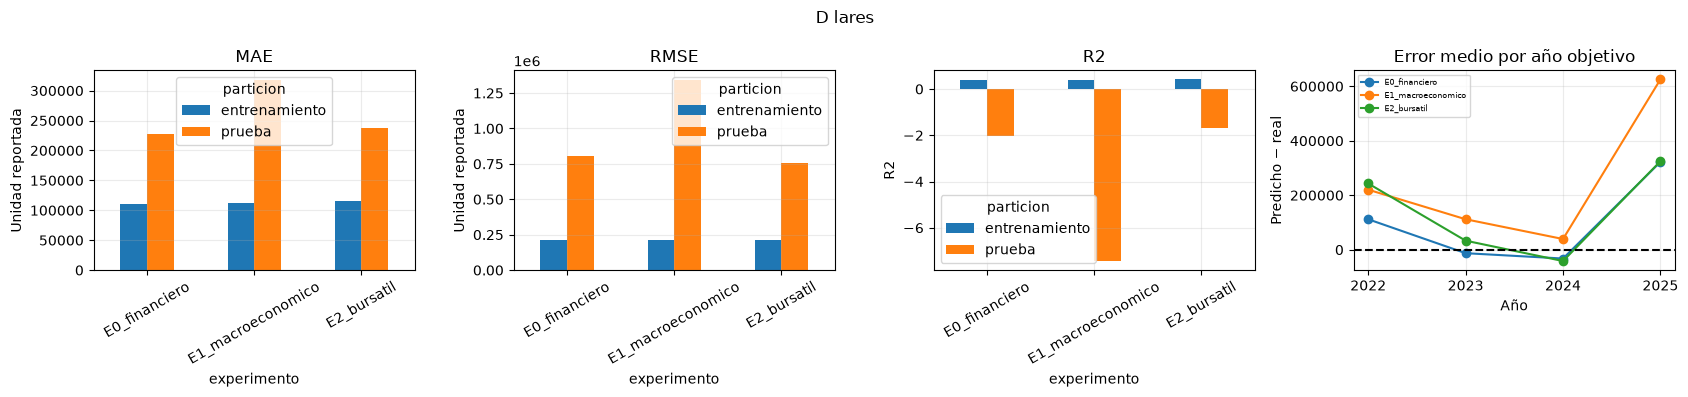

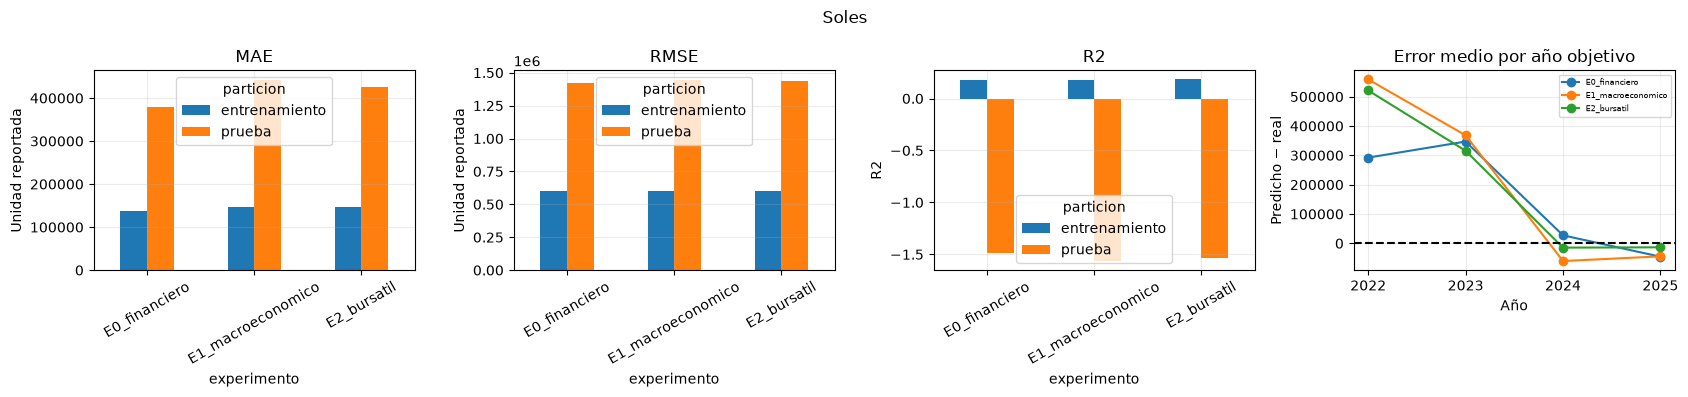

In [14]:
anuales=[]
for keys,g in pred.groupby(["escenario","moneda","experimento","particion","anio_objetivo"]):
    esc,mo,ex,pa,anio=keys
    anuales.append(dict(escenario=esc,moneda=mo,experimento=ex,particion=pa,anio_objetivo=int(anio),**metricas(g.y_real,g.y_predicho)))
metricas_anio=pd.DataFrame(anuales)
for moneda in monedas:
    fig,axs=plt.subplots(1,4,figsize=(17,4))
    for ax,m in zip(axs[:3],["MAE","RMSE","R2"]):
        g=principales.loc[principales.moneda.eq(moneda)].pivot(index="experimento",columns="particion",values=m)
        g.plot.bar(ax=ax,rot=30);ax.set(title=m,ylabel="R2" if m=="R2" else "Unidad reportada")
    g=metricas_anio.loc[metricas_anio.escenario.eq("principal")&metricas_anio.moneda.eq(moneda)&metricas_anio.particion.eq("prueba")]
    for exp,t in g.groupby("experimento"):axs[3].plot(t.anio_objetivo,t.error_medio,marker="o",label=exp)
    axs[3].axhline(0,color="black",linestyle="--");axs[3].set(title="Error medio por año objetivo",xlabel="Año",ylabel="Predicho − real");axs[3].set_xticks([2022,2023,2024,2025]);axs[3].legend(fontsize=6)
    fig.suptitle(moneda);fig.tight_layout();plt.show()
interpretaciones[14]="Se evalua prueba en 2022–2025, con errores por año objetivo y moneda. Las diferencias entre entrenamiento y prueba se muestran sin redefinir particiones."
etapas.append(14)

Se evalua prueba en 2022–2025, con errores por año objetivo y moneda. Las diferencias entre entrenamiento y prueba se muestran sin redefinir particiones.

**15. Desempeño por sector, revisiones y multicolinealidad**

Se reportan sectores con al menos 20 casos, sin modificar la muestra de evaluación. El rango y número de condición se calculan sobre X transformada de entrenamiento; no se eliminan variables usando prueba.

In [15]:
sector=[]
for keys,g in pred.loc[pred.escenario.eq("principal")].groupby(["moneda","experimento","particion","TipoSector"],dropna=False):
    mo,ex,pa,se=keys
    if len(g)>=20:sector.append(dict(moneda=mo,experimento=ex,particion=pa,sector=str(se),**metricas(g.y_real,g.y_predicho)))
metricas_sector=pd.DataFrame(sector)
revision=[]
for keys,g in pred.loc[pred.escenario.eq("principal")].groupby(["moneda","experimento","particion","revision_interanual"]):
    mo,ex,pa,rv=keys;revision.append(dict(moneda=mo,experimento=ex,particion=pa,revision_interanual=bool(rv),**metricas(g.y_real,g.y_predicho)))
metricas_revision=pd.DataFrame(revision)
colinealidad=[]
for moneda in monedas:
    t=muestra.loc[muestra.Moneda.eq(moneda)&muestra.particion.eq("entrenamiento")]
    for exp,cols in EXPERIMENTOS.items():
        p=modelos[("principal",moneda,exp)]
        z=p.named_steps["preparacion"].transform(t[cols]);s=np.linalg.svd(z,compute_uv=False)
        colinealidad.append({"moneda":moneda,"experimento":exp,"filas_train":len(t),"n_predictores":len(cols),"rango":int(np.linalg.matrix_rank(z)),"numero_condicion":float(s.max()/s.min()) if s.min()>0 else np.inf,"anios_train":t.Ejercicio.nunique()})
colinealidad=pd.DataFrame(colinealidad)
display(colinealidad.round(4))
display(metricas_sector.loc[metricas_sector.particion.eq("prueba")].round(3))
display(metricas_revision.loc[metricas_revision.particion.eq("prueba")].round(3))
interpretaciones[15]="Las matrices tienen rango completo 19/23/26. Numero de condicion: " + "; ".join(f"{m} {g.numero_condicion.min():.1f}–{g.numero_condicion.max():.1f}" for m,g in colinealidad.groupby('moneda')) + "; existe mayor sensibilidad numerica en soles."
etapas.append(15)

,moneda,experimento,filas_train,n_predictores,rango,numero_condicion,anios_train
0,D lares,E0_financiero,353,19,19,13.8217,16
1,D lares,E1_macroeconomico,353,23,23,13.8814,16
2,D lares,E2_bursatil,353,26,26,14.0084,16
3,Soles,E0_financiero,2516,19,19,210.5457,16
4,Soles,E1_macroeconomico,2516,23,23,215.0994,16
5,Soles,E2_bursatil,2516,26,26,221.4337,16


,moneda,experimento,particion,sector,n,MAE,RMSE,R2,error_medio
4,D lares,E0_financiero,prueba,DIVERSOS,21,419841.751,1523922.242,-15738.423,294744.420
5,D lares,E0_financiero,prueba,INDUSTRIALES,24,304115.465,626639.381,-0.784,233690.484
6,D lares,E0_financiero,prueba,MINERAS,42,109176.422,179312.972,0.882,-65948.977
11,D lares,E1_macroeconomico,prueba,DIVERSOS,21,722389.960,2712167.601,-49852.567,644917.816
12,D lares,E1_macroeconomico,prueba,INDUSTRIALES,24,340918.153,650343.171,-0.922,322949.501
13,D lares,E1_macroeconomico,prueba,MINERAS,42,130800.087,175230.113,0.888,30068.566
18,D lares,E2_bursatil,prueba,DIVERSOS,21,412190.073,1410283.435,-13478.569,323343.023
19,D lares,E2_bursatil,prueba,INDUSTRIALES,24,322089.949,640148.147,-0.862,271894.540
20,D lares,E2_bursatil,prueba,MINERAS,42,123021.879,184210.898,0.876,-13734.894
30,Soles,E0_financiero,prueba,AGRICOLAS,47,25542.697,33226.901,-0.007,15246.710


,moneda,experimento,particion,revision_interanual,n,MAE,RMSE,R2,error_medio
2,D lares,E0_financiero,prueba,False,74,131607.636,281027.875,0.625,-1070.227
3,D lares,E0_financiero,prueba,True,18,624557.586,1727840.822,-15.768,493247.049
6,D lares,E1_macroeconomico,prueba,False,74,159669.305,287773.628,0.606,91931.871
7,D lares,E1_macroeconomico,prueba,True,18,968871.140,2979745.748,-48.869,885430.870
10,D lares,E2_bursatil,prueba,False,74,146801.182,280224.950,0.627,46026.418
11,D lares,E2_bursatil,prueba,True,18,610421.852,1620312.326,-13.746,509840.129
14,Soles,E0_financiero,prueba,False,472,428827.697,1581555.865,-1.648,204450.342
15,Soles,E0_financiero,prueba,True,127,198423.715,526653.485,0.166,-14748.816
18,Soles,E1_macroeconomico,prueba,False,472,489363.001,1601891.904,-1.716,251482.157
19,Soles,E1_macroeconomico,prueba,True,127,267397.497,567057.078,0.033,52646.034


Las matrices tienen rango completo 19/23/26. Numero de condicion: D lares 13.8–14.0; Soles 210.5–221.4; existe mayor sensibilidad numerica en soles.

**16. Controles de fuga, igualdad de casos y reproducibilidad**

Se verifica que cada ajuste utiliza exclusivamente ids de entrenamiento y que la perturbación de prueba no cambia sus insumos. Se repite un ajuste determinista por moneda y se recalculan todas las métricas a partir de las predicciones.

In [16]:
for a in ajustes:
    expected=muestra.loc[muestra.Moneda.eq(a["moneda"])&muestra.particion.eq("entrenamiento"),"id_fila"].tolist()
    assert a["ids_ajuste"]==expected
    assert not set(a["ids_ajuste"]).intersection(set(muestra.loc[muestra.particion.eq("prueba"),"id_fila"]))
for moneda in monedas:
    cols=EXPERIMENTOS["E2_bursatil"]
    tr=muestra.loc[muestra.Moneda.eq(moneda)&muestra.particion.eq("entrenamiento")]
    te=muestra.loc[muestra.Moneda.eq(moneda)&muestra.particion.eq("prueba")]
    alterada=muestra.copy(deep=True)
    mask=alterada.particion.eq("prueba")
    alterada.loc[mask,cols]=alterada.loc[mask,cols]*100+1000
    alterada.loc[mask,"objetivo_fcl_t1"]*=100
    train_alterado=alterada.loc[tr.index]
    pd.testing.assert_frame_equal(train_alterado[cols],tr[cols],check_exact=True)
    repetido=clone(modelos[("principal",moneda,"E2_bursatil")]).fit(train_alterado[cols],train_alterado.objetivo_fcl_t1)
    np.testing.assert_allclose(repetido.predict(te[cols]),modelos[("principal",moneda,"E2_bursatil")].predict(te[cols]),rtol=1e-12,atol=1e-8)
for row in resultados.itertuples(index=False):
    g=pred.loc[pred.escenario.eq(row.escenario)&pred.moneda.eq(row.moneda)&pred.experimento.eq(row.experimento)&pred.particion.eq(row.particion)]
    calculado=metricas(g.y_real,g.y_predicho)
    for m in ["MAE","RMSE","R2","error_medio"]:np.testing.assert_allclose(getattr(row,m),calculado[m],rtol=1e-12,atol=1e-12,equal_nan=True)
assert np.isfinite(pred[["y_real","y_predicho","error"]]).all().all()
assert hashes_previos()==hashes_antes
print("Controles aprobados: ids, monedas, formulas, mismos casos, estadisticas train, perturbacion de prueba y hashes.")
interpretaciones[16]="Las 18 configuraciones usan exclusivamente sus ids de entrenamiento. Repetir E2 tras perturbar solo prueba conserva las predicciones de evaluacion y las metricas se reproducen desde las predicciones guardadas."
etapas.append(16)

Controles aprobados: ids, monedas, formulas, mismos casos, estadisticas train, perturbacion de prueba y hashes.


Las 18 configuraciones usan exclusivamente sus ids de entrenamiento. Repetir E2 tras perturbar solo prueba conserva las predicciones de evaluacion y las metricas se reproducen desde las predicciones guardadas.

**17. Exportación de resultados y limitaciones verificables**

Se exportan métricas, comparaciones, predicciones y diagnósticos sin cambiar los datos originales. El resumen incluye resultados numéricos por moneda; se verifica la relectura exacta y se registran las limitaciones metodológicas.

In [17]:
assert etapas==list(range(1,17))
limitaciones=[
    "Objetivo: FCO + CAPEX reportado en t+1; FCL preliminar, no FCFF validado. Linaje historico detallado de FCO/CAPEX y escala monetaria no acreditados.",
    "La etiqueta de moneda de dolares aparece como 'D lares' en el original. Se conserva; no se convierten monedas ni se agregan errores monetarios entre ellas.",
    "Dentro de cada moneda no se certifica homogeneidad de escala entre emisores; los valores absolutos y extremos pueden dominar MAE/RMSE. No se ajusta por tamaño ni se convierte el objetivo en ratio en esta entrega.",
    "No hay fechas efectivas de prediccion/publicacion ni vintages historicos de estados financieros o agregados. Las tres variantes principales son retrospectivas y condicionadas a disponibilidad; no se certifica backtest point-in-time.",
    "La sensibilidad externa t-1 mitiga simultaneidad, pero no elimina revisiones ni acredita disponibilidad del PBI u otros datos. La base externa 2004 incompleta se imputa solo con entrenamiento; no se descartan casos.",
    "Las particiones se conservan por anio_objetivo: entrenamiento hasta 2021 y prueba 2022–2025; no se optimizan alpha ni transformaciones con prueba. No hay validacion cruzada o estimacion de incertidumbre en esta etapa.",
    "Hay solo 16 años externos de entrenamiento y cuatro de prueba, con dependencia entre observaciones de una empresa. No se afirma significancia de diferencias ni superioridad generalizable.",
    "Bursatil: transicion metodologica de mayo 2015, discrepancias entre frecuencias y calendario diario no certificado; se conserva la definicion publicada, sin factores de correccion aprendidos.",
    "RobustScaler es sensibilidad predefinida de la penalizacion; no se usa prueba para sustituir la configuracion principal. No se eliminan ni winsorizan extremos.",
    "Los ratios/rezagos de FCL hasta t no usan la etiqueta t+1, pero sus fuentes pueden estar reexpresadas. Las revisiones no se resuelven mediante una verificacion algebraica.",
]
salidas={"resultados_experimentos.csv":resultados,"metricas_por_anio.csv":metricas_anio,"comparacion_variantes.csv":comparacion,
    "predicciones_baseline.csv":pred,"metricas_por_sector.csv":metricas_sector,"metricas_por_revision.csv":metricas_revision,
    "diagnostico_colinealidad.csv":colinealidad,"diagnostico_entrenamiento.csv":calidad}
inventario={}
for nombre,t in salidas.items():
    path=OUT/nombre;t.to_csv(path,index=False,encoding="utf-8",na_rep="")
    inventario[nombre]={"filas":len(t),"columnas":len(t.columns),"sha256":hashlib.sha256(path.read_bytes()).hexdigest()}
pred_leido=pd.read_csv(OUT/"predicciones_baseline.csv",dtype={"RPJ":"string","RUC":"string"},float_precision="round_trip")
pd.testing.assert_frame_equal(pred_leido,pred,check_dtype=False,check_exact=True)
res_leido=pd.read_csv(OUT/"resultados_experimentos.csv",float_precision="round_trip")
pd.testing.assert_frame_equal(res_leido,resultados,check_dtype=False,check_exact=True)
lineas=["Sprint 6: Ridge Baseline y variantes", "", "3560 observaciones: 2869 entrenamiento y 691 prueba. Se preservan 309 empresas elegibles y las particiones.",
    "19/23/26 predictores; alpha=1.0. Mediana + StandardScaler ajustados solo con entrenamiento. Modelos separados por moneda; unidades reportadas, escala no acreditada.", "", "Resultados principales de prueba:", "", "moneda | experimento | n | MAE | RMSE | R2 | error medio", "--- | --- | --- | --- | --- | --- | ---"]
for r in principales.loc[principales.particion.eq("prueba")].itertuples():lineas.append(f"{r.moneda} | {r.experimento} | {r.n} | {r.MAE:.4f} | {r.RMSE:.4f} | {r.R2:.6f} | {r.error_medio:.4f}")
lineas += ["", "Menor error por moneda y criterio:"]
for r in mejores.itertuples():lineas.append(f"{r.moneda}: {r.criterio}, {r.experimento}, {r.valor:.4f}.")
lineas += ["", "Sensibilidades: externos t-1 y RobustScaler, mismos casos y Ridge; resultados completos en comparacion_variantes.csv. Mejora porcentual positiva significa reduccion del error respecto a E0; denominador cero queda vacio.", "", "Limites:"]+limitaciones
(OUT/"resumen_experimentos.md").write_text("\n".join(lineas)+"\n",encoding="utf-8")
assert muestra.RPJ.nunique()==309
assert hashes_previos()==hashes_antes
def json_seguro(x):
    if isinstance(x,dict):return {str(k):json_seguro(v) for k,v in x.items()}
    if isinstance(x,(list,tuple)):return [json_seguro(v) for v in x]
    if isinstance(x,np.generic):return json_seguro(x.item())
    if isinstance(x,float) and not np.isfinite(x):return None
    return x
validacion={"estado":"EJECUTADO_CON_LIMITACIONES_METODOLOGICAS","fecha_utc":datetime.now(timezone.utc).isoformat(),"python":platform.python_version(),"versiones":versiones,
    "semilla":SEED,"alpha":ALPHA,"solver":"svd","observaciones_elegibles":len(muestra),"empresas_elegibles":int(muestra.RPJ.nunique()),
    "particiones":muestra.particion.value_counts().to_dict(),"conteos_por_moneda":conteos.reset_index().to_dict(orient="records"),
    "experimentos":EXPERIMENTOS,"exclusiones_por_redundancia":sorted(redundantes),"escenarios":["principal","rezago_externo_t_1","sensibilidad_robust"],
    "n_modelos":len(modelos),"n_predicciones":len(pred),"configuraciones_ajuste":ajustes,"mejores_principales":mejores.to_dict(orient="records"),
    "metricas_principales":principales.to_dict(orient="records"),"distribucion_objetivo_train":distribucion.to_dict(orient="records"),
    "controles":{"objetivo_t_mas_1_verificado":True,"mismas_filas_entre_experimentos":True,"monedas_separadas":True,"sin_objetivo_ni_anio_objetivo_en_X":True,
        "sin_ajuste_en_prueba":True,"imputadores_verificados_con_train":True,"escaladores_verificados_con_train":True,"rezagos_anuales_exactos":True,
        "sin_predicciones_infinitas":True,"metricas_recalculadas":True,"relectura_exacta":True,"sin_eliminacion_por_faltantes_X":True,"archivos_previos_preservados":True},
    "disponibilidad_real_historica":"NO_VERIFICADA","escala_monetaria":"NO_ACREDITADA","limitaciones":limitaciones,
    "archivos_revisados":revisados,"archivos_previos":hashes_antes,"inventario":inventario,"interpretaciones":interpretaciones,
    "ejecucion":{"bloques_codigo":17,"bloques_previos_completados":etapas.copy()}}
(OUT/"validacion_baseline.json").write_text(json.dumps(json_seguro(validacion),ensure_ascii=False,indent=2,allow_nan=False)+"\n",encoding="utf-8")
print("Reportes guardados:",OUT.relative_to(ROOT))
print("Muestra:",len(muestra),"| Modelos:",len(modelos),"| Predicciones:",len(pred))
print("Originales, paneles, README y notebooks anteriores intactos.")
etapas.append(17)

Reportes guardados: reports/sprint_06
Muestra: 3560 | Modelos: 18 | Predicciones: 32040
Originales, paneles, README y notebooks anteriores intactos.


Los archivos exportados contienen las métricas principales y las dos sensibilidades, con predicciones para verificarlas. La ejecución conserva los originales y registra explícitamente la disponibilidad y escala monetaria no verificadas.